# Computer Vision

Let's do some very basic computer vision. We're going to import the MNIST handwritten digits data and $k$NN to predict values (i.e. "see/read").

1. To load the data, run the following code in a chunk:
```
import pickle
with open('data/minst.pkl', 'rb') as f:
    data = pickle.load(f)
X_train, y_train = data['X_train'], data['y_train']
X_test, y_test = data['X_test'], data['y_test']
```
The `y_test` and `y_train` vectors, for each index `i`, tell you want number is written in the corresponding index in `X_train[i]` and `X_test[i]`. The value of `X_train[i]` and `X_test[i]`, however, is a 28$\times$28 array whose entries contain values between 0 and 256. Each element of the matrix is essentially a "pixel" and the matrix encodes a representation of a number. To visualize this, run the following code to see the first ten numbers:
```
import matplotlib.pyplot as plt
import numpy as np
np.set_printoptions(edgeitems=30, linewidth=100000)
for i in range(5): 
    print(y_test[i],'\n') # Print the label
    print(X_test[i],'\n') # Print the matrix of values
    plt.contourf(np.rot90(X_test[i].transpose())) # Make a contour plot of the matrix values
    plt.show()
```
OK, those are the data: Labels attached to handwritten digits encoded as a matrix.

2. What is the shape of `X_train` and `X_test`? What is the shape of `X_train[i]` and `X_test[i]` for each index `i`? What is the shape of `y_train` and `y_test`?
3. Use Numpy's `.reshape()` method to covert the training and testing data from a matrix into an vector of features. So, `X_test[index].reshape((1,784))` will convert the $index$-th element of `X_test` into a $28\times 28=784$-length row vector of values, rather than a matrix. Turn `X_train` into an $N \times 784$ matrix $X$ that is suitable for scikit-learn's kNN classifier where $N$ is the number of observations and $784=28*28$ (you could use, for example, a `for` loop).
4. Use the reshaped `X_test` and `y_test` data to create a $k$-nearest neighbor classifier of digit. What is the optimal number of neighbors $k$? If you can't determine this, play around with different values of $k$ for your classifier.
5. For the optimal number of neighbors, how well does your predictor perform on the test set? Report the accuracy, compute a confusion matrix, and explain your findings.
6. For your confusion matrix, which mistakes are most likely? Do you find any interesting patterns?
7. So, this is how computers "see." They convert an image into a matrix of values, that matrix becomes a vector in a dataset, and then we deploy ML tools on it as if it was any other kind of tabular data. To make sure you follow this, invent a way to represent a color photo in matrix form, and then describe how you could convert it into tabular data. (Hint: RGB color codes provide a method of encoding a numeric value that represents a color.)

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** Emma Chung, Kevin Sun, Anastacia Oliynyk

**Date:** 11/2/2026

In [1]:
%pip install numpy
%pip install matplotlib seaborn scipy
%pip install scikit-learn
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier


[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.

[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.

[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [2]:
import zipfile

with zipfile.ZipFile("data.zip") as archive:
    archive.extractall(".")

In [3]:
import pickle

with open('data/minst.pkl', 'rb') as f:
    data = pickle.load(f)

X_train, y_train = data['X_train'], data['y_train']
X_test, y_test = data['X_test'], data['y_test']

7 

[[  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0  84 185 159 151  60  36   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0 222 254 254 254 254 241 198 198 198 198 198 198 19

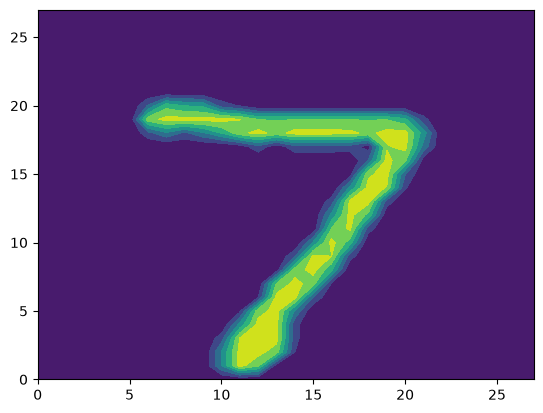

2 

[[  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0 116 125 171 255 255 150  93   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0 169 253 253 253 253 253 253 218  30   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0 169 253 253 253 213 142 176 253 253 122   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0  52 250 253 210  32  12   0   6 206 253 140   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0  77 251 210  25   0   0   0 122 248 253  65   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0  31  18   0   0   0   0 209 253 253  65   

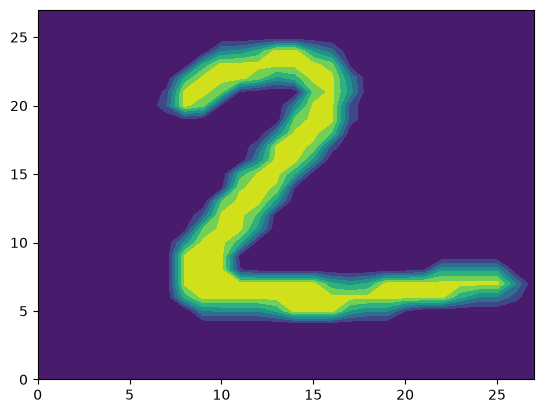

1 

[[  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0  38 254 109   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0  87 252  82   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0 135 241   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0  45 244 150   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0  84 254  63   

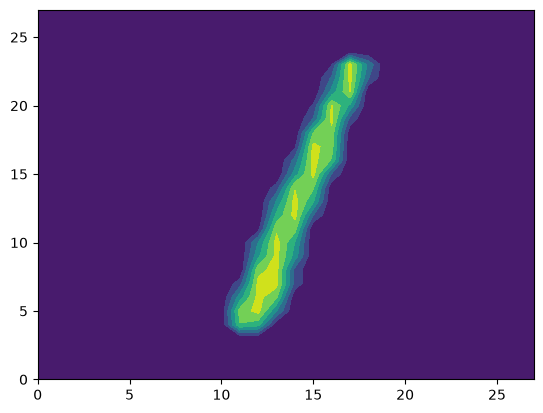

0 

[[  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0  11 150 253 202  31   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0  37 251 251 253 107   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0  21 197 251 251 253 107   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0 110 190 251 251 251 253 169 109  62   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0 253 251 251 251 251 253 251 251 22

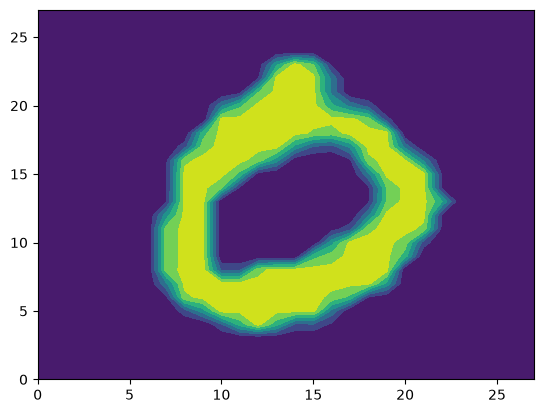

4 

[[  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0  50 224   0   0   0   0   0   0   0  70  29   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0 121 231   0   0   0   0   0   0   0 148 168   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   4 195 231   0   0   0   0   0   0   0  96 210  11   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0  69 252 134   0   0   0   0   0   0   

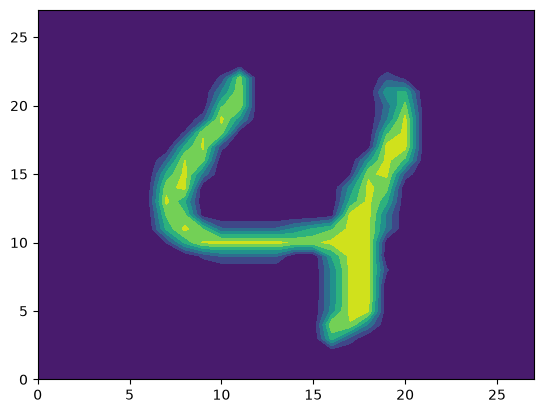

In [4]:
import matplotlib.pyplot as plt

np.set_printoptions(edgeitems=30, linewidth=100000)

for i in range(5):
    print(y_test[i], '\n')
    print(X_test[i], '\n')
    plt.contourf(np.rot90(X_test[i].transpose()))
    plt.show()

Q2.

In [5]:
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)

print("One training image:", X_train[0].shape)
print("One test image:", X_test[0].shape)

print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (60000, 28, 28)
X_test: (10000, 28, 28)
One training image: (28, 28)
One test image: (28, 28)
y_train: (60000,)
y_test: (10000,)


X_train has shape (60000, 28, 28) and X_test has shape (10000, 28, 28). Each image has shape (28, 28), representing 784 grayscale pixels. y_train has shape (60000,) and y_test has shape (10000,), with one digit label per image.

Q3.

In [6]:
X = X_train.reshape(len(X_train), 784).astype(np.float32)
X_test_flat = X_test.reshape(len(X_test), 784).astype(np.float32)

print("Flattened training data:", X.shape)
print("Flattened test data:", X_test_flat.shape)

Flattened training data: (60000, 784)
Flattened test data: (10000, 784)


The flattened training matrix has shape (60000, 784), and the flattened test matrix has shape (10000, 784). Each row represents one image, and each column represents a pixel position.

Q4. 

In [7]:
from sklearn.metrics import accuracy_score

X_fit, X_val, y_fit, y_val = train_test_split(
    X,
    y_train,
    train_size=12000,
    test_size=3000,
    random_state=42,
    stratify=y_train
)

scores = {}

for k in [1, 3, 5, 7, 9]:
    knn = KNeighborsClassifier(
        n_neighbors=k,
        algorithm="brute",
        n_jobs=-1
    )
    knn.fit(X_fit, y_fit)
    val_predictions = knn.predict(X_val)
    scores[k] = accuracy_score(y_val, val_predictions)

    print(f"k = {k}: validation accuracy = {scores[k]:.2%}")

best_k = max(scores, key=scores.get)
print("Best k:", best_k)

k = 1: validation accuracy = 95.20%
k = 3: validation accuracy = 95.03%
k = 5: validation accuracy = 94.53%
k = 7: validation accuracy = 94.60%
k = 9: validation accuracy = 94.30%
Best k: 1


On this validation split, k = 1 achieved the highest accuracy, at 95.20%. It was the best of the values tested, although this does not prove it is optimal across all possible values or validation splits. A subset of the training data was used to make the comparison faster.

Q5. 

Test accuracy: 96.91%
[[ 973    1    1    0    0    1    3    1    0    0]
 [   0 1129    3    0    1    1    1    0    0    0]
 [   7    6  992    5    1    0    2   16    3    0]
 [   0    1    2  970    1   19    0    7    7    3]
 [   0    7    0    0  944    0    3    5    1   22]
 [   1    1    0   12    2  860    5    1    6    4]
 [   4    2    0    0    3    5  944    0    0    0]
 [   0   14    6    2    4    0    0  992    0   10]
 [   6    1    3   14    5   13    3    4  920    5]
 [   2    5    1    6   10    5    1   11    1  967]]


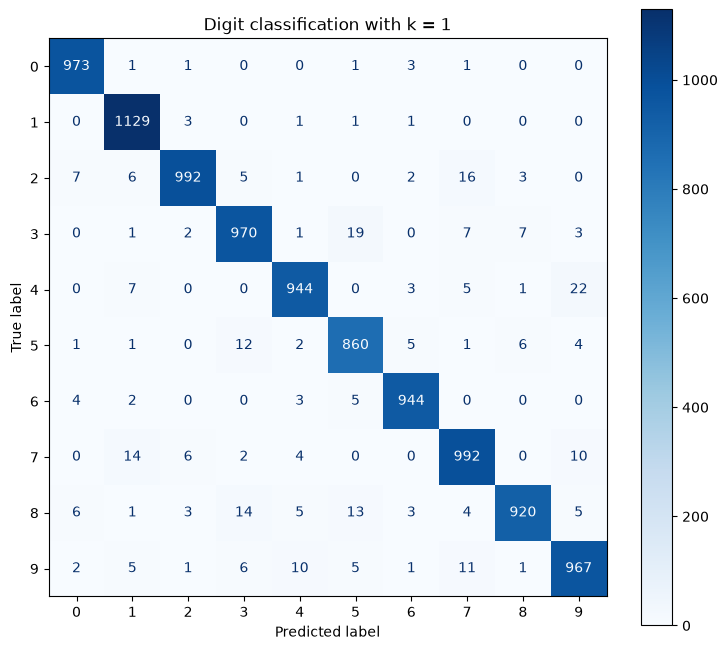

In [8]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

model = KNeighborsClassifier(
    n_neighbors=best_k,
    algorithm="brute",
    n_jobs=-1
)

model.fit(X, y_train)
y_pred = model.predict(X_test_flat)

accuracy = accuracy_score(y_test, y_pred)
print(f"Test accuracy: {accuracy:.2%}")

cm = confusion_matrix(y_test, y_pred, labels=np.arange(10))
print(cm)

fig, ax = plt.subplots(figsize=(9, 8))
ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=np.arange(10)
).plot(ax=ax, cmap="Blues", values_format="d")

plt.title(f"Digit classification with k = {best_k}")
plt.show()

With k = 1, the classifier correctly predicted 9,691 of the 10,000 test images, giving 96.91% accuracy. In the confusion matrix, rows represent actual digits and columns represent predicted digits. Most observations lie on the diagonal, meaning the model correctly classifies most images. Off-diagonal entries represent mistakes.

Q6. 

In [9]:
errors = cm.copy()
np.fill_diagonal(errors, 0)

# Sort the off-diagonal counts from largest to smallest.
indices = np.argsort(-errors.ravel(), kind="stable")[:5]

for index in indices:
    actual, predicted = np.unravel_index(index, errors.shape)
    print(
        f"Actual {actual}, predicted {predicted}: "
        f"{errors[actual, predicted]} mistakes"
    )

Actual 4, predicted 9: 22 mistakes
Actual 3, predicted 5: 19 mistakes
Actual 2, predicted 7: 16 mistakes
Actual 7, predicted 1: 14 mistakes
Actual 8, predicted 3: 14 mistakes


The most frequent mistakes were 4 being classified as 9 (22 cases), 3 as 5 (19 cases), and 2 as 7 (16 cases). These digits can share similar handwritten strokes, which may explain some confusion. Errors are directional: 4 was classified as 9 more frequently than 9 was classified as 4. Because kNN compares pixel values, differences in handwriting and image alignment can affect predictions.

Q7. 

I would represent a color photo as a three-dimensional array with shape (height, width, 3). Each pixel contains three values for its red, green, and blue intensities, usually between 0 and 255. For example, a 28 × 28 color image would have shape (28, 28, 3).

To turn the photos into tabular data, I would flatten each image into a vector of 2,352 values (28 × 28 × 3). Each row would represent one photo, and each column would represent a particular pixel’s color channel. All photos would need the same dimensions and consistent pixel and channel ordering. Any labels would be stored separately.

## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** 78bc8e895842933a46168ad683e5eb8ba53dc83a
- **AI tool and model used:** ChatGPT-GPT-6

### *Prompts used

1. Hey chat I'm working on some data science questions. Here is the list of all the questions [pastes in the entirety of all questions 1-7]. I've already ran the code for Question 1 so you don't need to worry about that. Let's start with Question 2 [pastes in code for Question 2]. For all the questions can you just check to see if my code is correct or if I can make the code more efficient? You don’t need to worry about any of the analysis questions. Lastly, I’ve already imported and installed all the tools I need like numpy, matplotlib, etc
2. Onto Question 3 [pastes in code for Question 3], can you check the code for this please?
3. Now onto Question 4. Here is my code [pastes in code for Question 4].
4. Now onto Question 5. Here is my code [pastes in code for Question 5].
5. Now onto, Question 6. Here is my code [pastes in code for Question 6].
6. Lastly, can you check to see if this explanation for Question 7 makes sense?

### *AI-proposed changes


[Paste the AI's concise numbered list verbatim.]

1. I'd suggest just one small improvement: use -1 in .reshape() to make your code a little cleaner. (Q3)
2. Consider testing more values of k. (Q4)
3. Simplify the accuracy calculation. Scikit-learn's classifier has a .score() method that calculates accuracy for classification problems. (Q4)
4. I'd consider changing the output slightly so it's easier to interpret when writing your answer. This is purely a readability improvement. (Q6)

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Accept | This just makes the code more concise and clean. Verified by comparing this new code output to our original code output to see if they matched which they did |
| 2 | Accept | Testing more values of k is never a bad idea if we're trying to find optimal values of k. We are now testing odd values of k from 1-15. Verified by seeing if the accuracy calculation for k-values 1-9 matched what we originally got which it did. Therefore, subsequent k-value calculations should also be correct |
| 3 | Accept | Simplifying the accuracy calculation from two lines to one line of code just makes the code more concise and clean. Verified by comparing this new code output to our original code output to see if they matched which they did |
| 4 | Accept | Making output more clear/readable is never a bad suggestion. Verified by making sure the new code AI gave me only changed the wording of the output and not the content of the output which it did |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

In [10]:
# Your Phase 2 solution to the problem goes here.


Q1

In [11]:
import zipfile

with zipfile.ZipFile("data.zip") as archive:
    archive.extractall(".")

In [12]:
import pickle

with open('data/minst.pkl', 'rb') as f:
    data = pickle.load(f)

X_train, y_train = data['X_train'], data['y_train']
X_test, y_test = data['X_test'], data['y_test']

7 

[[  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0  84 185 159 151  60  36   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0 222 254 254 254 254 241 198 198 198 198 198 198 19

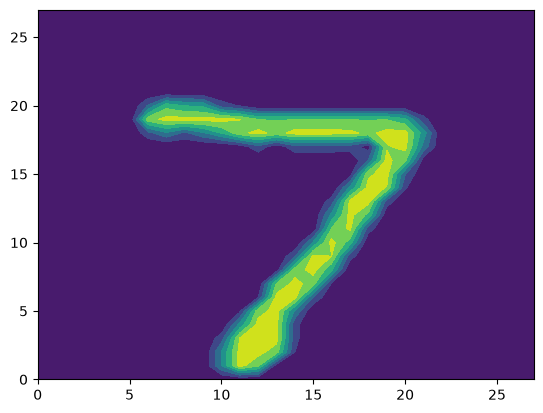

2 

[[  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0 116 125 171 255 255 150  93   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0 169 253 253 253 253 253 253 218  30   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0 169 253 253 253 213 142 176 253 253 122   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0  52 250 253 210  32  12   0   6 206 253 140   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0  77 251 210  25   0   0   0 122 248 253  65   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0  31  18   0   0   0   0 209 253 253  65   

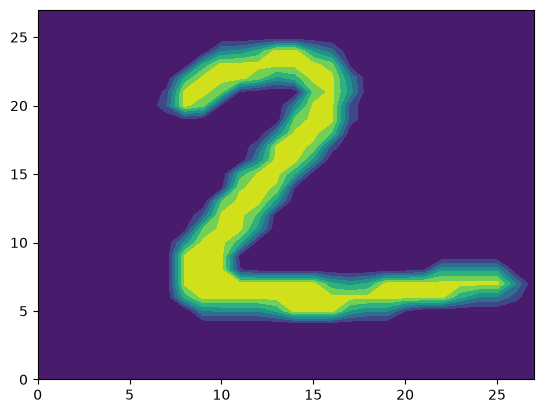

1 

[[  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0  38 254 109   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0  87 252  82   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0 135 241   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0  45 244 150   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0  84 254  63   

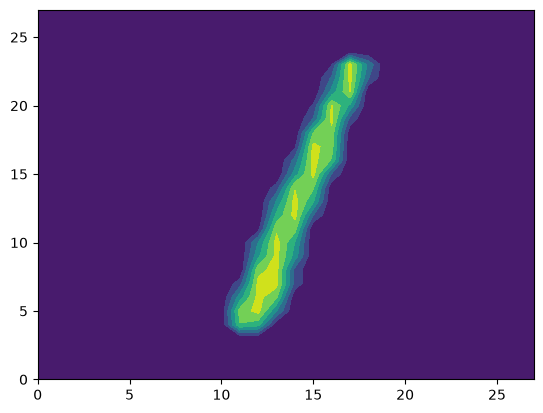

0 

[[  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0  11 150 253 202  31   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0  37 251 251 253 107   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0  21 197 251 251 253 107   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0 110 190 251 251 251 253 169 109  62   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0 253 251 251 251 251 253 251 251 22

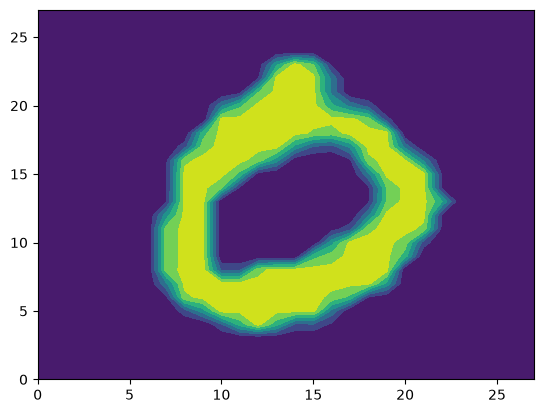

4 

[[  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0  50 224   0   0   0   0   0   0   0  70  29   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0 121 231   0   0   0   0   0   0   0 148 168   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   4 195 231   0   0   0   0   0   0   0  96 210  11   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0  69 252 134   0   0   0   0   0   0   

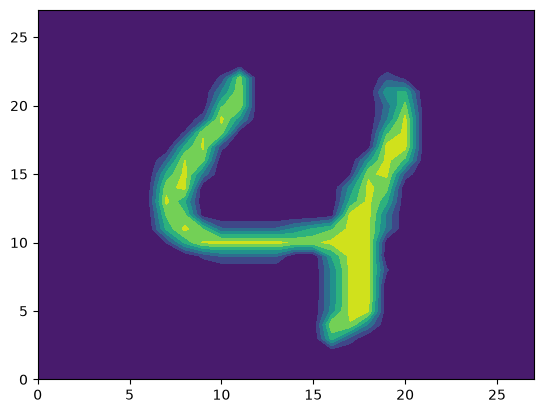

In [13]:
import matplotlib.pyplot as plt

np.set_printoptions(edgeitems=30, linewidth=100000)

for i in range(5):
    print(y_test[i], '\n')
    print(X_test[i], '\n')
    plt.contourf(np.rot90(X_test[i].transpose()))
    plt.show()

Q2

In [14]:
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)

print("One training image:", X_train[0].shape)
print("One test image:", X_test[0].shape)

print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (60000, 28, 28)
X_test: (10000, 28, 28)
One training image: (28, 28)
One test image: (28, 28)
y_train: (60000,)
y_test: (10000,)


Q3

In [15]:
X = X_train.reshape(-1, 784).astype(np.float32)
X_test_flat = X_test.reshape(-1, 784).astype(np.float32)

print("Flattened training data:", X.shape)
print("Flattened test data:", X_test_flat.shape)

Flattened training data: (60000, 784)
Flattened test data: (10000, 784)


Q4

In [16]:
X_fit, X_val, y_fit, y_val = train_test_split(
    X,
    y_train,
    train_size=12000,
    test_size=3000,
    random_state=42,
    stratify=y_train
)

scores = {}

for k in range(1, 16, 2):
    knn = KNeighborsClassifier(
        n_neighbors=k,
        algorithm="brute",
        n_jobs=-1
    )
    knn.fit(X_fit, y_fit)
    scores[k] = knn.score(X_val, y_val)

    print(f"k = {k}: validation accuracy = {scores[k]:.2%}")

best_k = max(scores, key=scores.get)
print("Best k:", best_k)

k = 1: validation accuracy = 95.20%
k = 3: validation accuracy = 95.03%
k = 5: validation accuracy = 94.53%
k = 7: validation accuracy = 94.60%
k = 9: validation accuracy = 94.30%
k = 11: validation accuracy = 93.73%
k = 13: validation accuracy = 93.43%
k = 15: validation accuracy = 93.17%
Best k: 1


Q5

Test accuracy: 96.91%
[[ 973    1    1    0    0    1    3    1    0    0]
 [   0 1129    3    0    1    1    1    0    0    0]
 [   7    6  992    5    1    0    2   16    3    0]
 [   0    1    2  970    1   19    0    7    7    3]
 [   0    7    0    0  944    0    3    5    1   22]
 [   1    1    0   12    2  860    5    1    6    4]
 [   4    2    0    0    3    5  944    0    0    0]
 [   0   14    6    2    4    0    0  992    0   10]
 [   6    1    3   14    5   13    3    4  920    5]
 [   2    5    1    6   10    5    1   11    1  967]]


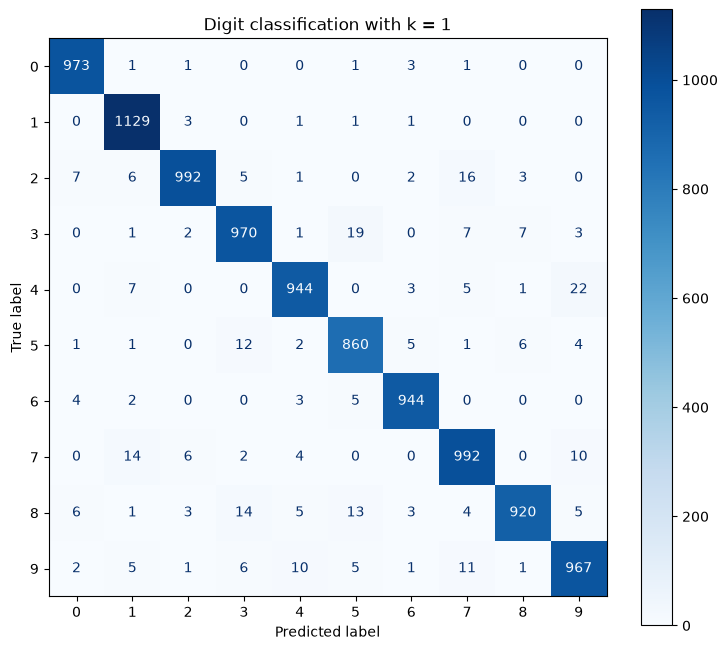

In [17]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

model = KNeighborsClassifier(
    n_neighbors=best_k,
    algorithm="brute",
    n_jobs=-1
)

model.fit(X, y_train)
y_pred = model.predict(X_test_flat)

accuracy = accuracy_score(y_test, y_pred)
print(f"Test accuracy: {accuracy:.2%}")

cm = confusion_matrix(y_test, y_pred, labels=np.arange(10))
print(cm)

fig, ax = plt.subplots(figsize=(9, 8))
ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=np.arange(10)
).plot(ax=ax, cmap="Blues", values_format="d")

plt.title(f"Digit classification with k = {best_k}")
plt.show()

Q6

In [18]:
errors = cm.copy()
np.fill_diagonal(errors, 0)

# Find the five most common classification errors.
indices = np.argsort(-errors.ravel(), kind="stable")[:5]

for index in indices:
    actual, predicted = np.unravel_index(index, errors.shape)
    print(
        f"Digit {actual} misclassified as {predicted}: "
        f"{errors[actual, predicted]} times"
    )

Digit 4 misclassified as 9: 22 times
Digit 3 misclassified as 5: 19 times
Digit 2 misclassified as 7: 16 times
Digit 7 misclassified as 1: 14 times
Digit 8 misclassified as 3: 14 times


**Since the content of AI’s output matched what we got originally, all of our analysis above for the questions (2-7) still hold true.**

### *Reflection on AI assistance
In your own words without generative AI.

[In 150–300 words, describe the main improvements, AI mistakes or limitations, how the final solution was verified, and any remaining concerns.]

The main improvements AI helped us with for this lab was making our code more concise and clean. AI did this by shortening some of our code blocks and suggesting more efficient ways to accomplish the same tasks using built-in methods, while still preserving the output/content of our original code. Additionally, AI also helped us make some of our outputs more clear and easy to interpret by refining the wording in some of our print statements. AI could do both of these improvements well because AI is great at code optimization (has knowledge of more efficient coding methods that our team did not originally know) and is also good at summarizing information (wording). One limitation of AI during this lab was that it sometimes suggested improvements that were not necessarily needed to accomplish the task. For example, AI suggested testing additional values of k to potentially find a more optimal k-value. Although we followed this suggestion (since it did not hurt our results), we ultimately still stuck with k = 1, which was already the best performing value in our original selection. We verified the final solution by comparing AI’s output to our own code’s output to see if they matched and they did. We have no remaining concerns for this lab.